# Tversky-mLSTM vs vanilla xLSTM

In [1]:
# --no-deps: the legacy xLSTM blocks need only torch; this avoids pulling mlstm_kernels/triton and touching Kaggle's torch
!pip install -q --no-deps xlstm==2.0.6

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.1/92.1 kB 2.6 MB/s eta 0:00:00


In [2]:
import os, gc, glob, json, math, random, time, urllib.request, warnings
from copy import deepcopy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from xlstm import (xLSTMLMModel, xLSTMLMModelConfig, mLSTMBlockConfig, mLSTMLayerConfig,
                   sLSTMBlockConfig, sLSTMLayerConfig, FeedForwardConfig)
from xlstm.blocks.mlstm.cell import mLSTMCell

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.__version__, DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

2.11.0+cu128 cuda Tesla T4


## Config

In [ ]:
DRY_RUN = False          # True: tiny slice of PTB, 1 epoch, 1 seed

SEEDS = [0, 1, 2]
CTX = 256
BATCH_SIZE = 32
EPOCHS = 15             
LR = 1.5e-3
WEIGHT_DECAY = 0.1
BETAS = (0.9, 0.95)
WARMUP_FRAC = 0.05
DROPOUT = 0.1
CLIP = 1.0
USE_AMP = True
TIME_BUDGET_H = 11.0
PHASES = (1,2)            # (1,) = core comparison only; (1, 2) adds the same-shape control and mode ablations
BENCH_STEPS = 30

EMBED_DIM = 256
NUM_TVERSKY_FEATURES = 64
TVERSKY_OUTPUT_DIM = 64

SLSTM_AT = {8: [1, 5], 4: [1]}

ARMS = [
    dict(name="xl_L8",           phase=1, kind="standard", blocks=8, dim=EMBED_DIM),
    dict(name="tvy_L4_prod_ign", phase=1, kind="tversky",  blocks=4, dim=EMBED_DIM, inter="product", diff="ignorematch"),
    dict(name="xl_L4_wide",      phase=1, kind="standard", blocks=4, dim="match:tvy_L4_prod_ign"),
    dict(name="tvy_L4_prod_ign_all", phase=1, kind="tversky", blocks=4, dim=EMBED_DIM, inter="product", diff="ignorematch", wrap_slstm=True),
    dict(name="xl_L4_wide_all",  phase=1, kind="standard", blocks=4, dim="match:tvy_L4_prod_ign_all"),
    dict(name="tvy_L4_prod_sub", phase=1, kind="tversky",  blocks=4, dim=EMBED_DIM, inter="product", diff="substractmatch"),
    dict(name="xl_L4",           phase=2, kind="standard", blocks=4, dim=EMBED_DIM),
    dict(name="tvy_L4_min_ign",  phase=2, kind="tversky",  blocks=4, dim=EMBED_DIM, inter="min",  diff="ignorematch"),
    dict(name="tvy_L4_mean_ign", phase=2, kind="tversky",  blocks=4, dim=EMBED_DIM, inter="mean", diff="ignorematch"),
]

OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
RESULTS = os.path.join(OUT_DIR, "results_lm.jsonl")
DATA_DIR = "/kaggle/temp/ptb" if os.path.exists("/kaggle") else "./ptb"

if DRY_RUN:
    SEEDS, EPOCHS, BENCH_STEPS = [0], 1, 3
    RESULTS = os.path.join(OUT_DIR, "results_lm_dryrun.jsonl")


def set_seed(seed_value=42):
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

## Tversky similarity

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint


@torch.jit.script
def fused_tversky_score(a_fk: torch.Tensor,
                        b_fk: torch.Tensor,
                        constants: torch.Tensor,
                        diff_mode_sub: bool) -> torch.Tensor:
    mask_intersect = (a_fk > 0) & (b_fk > 0)
    intersection = torch.where(mask_intersect, a_fk * b_fk, 0.0)

    if diff_mode_sub:
        mask_ab = mask_intersect & (a_fk > b_fk)
        diff_ab = torch.where(mask_ab, a_fk - b_fk, 0.0)

        mask_ba = mask_intersect & (b_fk > a_fk)
        diff_ba = torch.where(mask_ba, b_fk - a_fk, 0.0)
    else:
        mask_ab = (a_fk > 0) & (b_fk <= 0)
        diff_ab = torch.where(mask_ab, a_fk, 0.0)

        mask_ba = (b_fk > 0) & (a_fk <= 0)
        diff_ba = torch.where(mask_ba, b_fk, 0.0)

    weighted_elements = (intersection * constants[0] +
                         diff_ab * constants[1] +
                         diff_ba * constants[2])

    return torch.sum(weighted_elements, dim=-1)


INTERSECTION_MODES = ("product", "min", "max", "mean", "gmean", "softmin")
MATMUL_INTERSECTIONS = ("product", "mean", "gmean")


def _psi(a, b, mode: str):
    """Intersection reduction Psi(a.f_k, b.f_k) from the paper."""
    if mode == "product":
        return a * b
    if mode == "min":
        return torch.minimum(a, b)
    if mode == "max":
        return torch.maximum(a, b)
    if mode == "mean":
        return 0.5 * (a + b)
    if mode == "gmean":
        return torch.sqrt((a * b).clamp_min(1e-8))
    if mode == "softmin":
        return -torch.logaddexp(-a, -b)
    raise ValueError(mode)


def tversky_score_pairwise(a_fk, b_fk, constants, intersection_mode: str, diff_mode_sub: bool):
    """Broadcast implementation, generalised to every intersection mode.
    With intersection_mode='product' this is exactly fused_tversky_score."""
    mask_intersect = (a_fk > 0) & (b_fk > 0)
    intersection = torch.where(mask_intersect, _psi(a_fk, b_fk, intersection_mode), 0.0)
    if diff_mode_sub:
        diff_ab = torch.where(mask_intersect & (a_fk > b_fk), a_fk - b_fk, 0.0)
        diff_ba = torch.where(mask_intersect & (b_fk > a_fk), b_fk - a_fk, 0.0)
    else:
        diff_ab = torch.where((a_fk > 0) & (b_fk <= 0), a_fk, 0.0)
        diff_ba = torch.where((b_fk > 0) & (a_fk <= 0), b_fk, 0.0)
    return (intersection * constants[0] + diff_ab * constants[1] + diff_ba * constants[2]).sum(-1)


def tversky_score_matmul(a_fk, b_fk, constants, intersection_mode: str):
    """ignorematch + {product, mean, gmean} as three (or four) matmuls.
    a_fk: (..., 1, K) input features, b_fk: (1, ..., 1, P, K) shared prototype features.
    Identical to the broadcast version because every masked term factorises:
      product: sum_k 1[a>0]1[b>0] a b         = relu(a) @ relu(b)^T
      mean:    sum_k 1[a>0]1[b>0] (a+b)/2     = 0.5 (relu(a) @ 1[b>0]^T + 1[a>0] @ relu(b)^T)
      A-B:     sum_k 1[a>0]1[b<=0] a          = relu(a) @ 1[b<=0]^T
      B-A:     sum_k 1[b>0]1[a<=0] b          = 1[a<=0] @ relu(b)^T
    """
    a = a_fk.squeeze(-2)                      # (..., K)
    b = b_fk.reshape(-1, b_fk.shape[-1])      # (P, K)
    ra, rb = F.relu(a), F.relu(b)
    pa, pb = (a > 0).to(a.dtype), (b > 0).to(b.dtype)
    if intersection_mode == "product":
        inter = ra @ rb.t()
    elif intersection_mode == "mean":
        inter = 0.5 * (ra @ pb.t() + pa @ rb.t())
    elif intersection_mode == "gmean":
        inter = torch.sqrt(ra.clamp_min(1e-8)) * pa @ (torch.sqrt(rb.clamp_min(1e-8)) * pb).t()
    else:
        raise ValueError(intersection_mode)
    diff_ab = ra @ (1.0 - pb).t()
    diff_ba = (1.0 - pa) @ rb.t()
    return inter * constants[0] + diff_ab * constants[1] + diff_ba * constants[2]


def tversky_score(a_fk, b_fk, constants, intersection_mode, diff_mode_sub, impl="auto", training=True):
    shared_protos = all(s == 1 for s in b_fk.shape[:-2])
    use_matmul = (impl in ("auto", "matmul") and shared_protos and not diff_mode_sub
                  and intersection_mode in MATMUL_INTERSECTIONS)
    if use_matmul:
        return tversky_score_matmul(a_fk, b_fk, constants, intersection_mode)
    if impl == "fused" and intersection_mode == "product":
        return fused_tversky_score(a_fk, b_fk, constants, diff_mode_sub)
    fn = lambda a, b, c: tversky_score_pairwise(a, b, c, intersection_mode, diff_mode_sub)
    if training and torch.is_grad_enabled():
        # recompute the (B, T, P, K) intermediates in backward instead of storing them
        return checkpoint(fn, a_fk, b_fk, constants, use_reentrant=False)
    return fn(a_fk, b_fk, constants)


class TverskySimilarity(nn.Module):
    def __init__(self, feats: torch.Tensor, intersection_mode: str = "product",
                 difference_mode: str = "ignorematch", impl: str = "auto"):
        super().__init__()
        assert intersection_mode in INTERSECTION_MODES, intersection_mode
        assert difference_mode in ("ignorematch", "substractmatch"), difference_mode
        self.feats = feats
        self.intersection_mode = intersection_mode
        self.difference_mode = difference_mode
        self.use_sub_match = (difference_mode == "substractmatch")
        self.impl = impl

        self.constants = nn.Parameter(torch.tensor([1.0, -1.0, -1.0]), requires_grad=True)

    def forward(self, a: torch.Tensor, b_batch: torch.Tensor) -> torch.Tensor:
        """
        a: (B, T, D) - RNN Input
        b_batch: (B, T, P, D) - Dynamic Projections
        """
        feats_T = self.feats.t()  # (D, K)

        # (B, T, 1, K)
        if a.dim() == 3:
            B, T, D = a.shape
            a_flat = a.reshape(B * T, D)
            a_fk = torch.matmul(a_flat, feats_T).reshape(B, T, 1, -1)
        else:
            a_fk = torch.matmul(a, feats_T).unsqueeze(1)

        # (B, T, P, K)
        if b_batch.dim() == 4:
            B, T, P, D = b_batch.shape
            b_flat = b_batch.reshape(B * T * P, D)
            b_fk = torch.matmul(b_flat, feats_T).reshape(B, T, P, -1)
        else:
            b_fk = torch.matmul(b_batch, feats_T)

        return tversky_score(a_fk, b_fk, self.constants, self.intersection_mode,
                             self.use_sub_match, self.impl, self.training)

## Tversky-mLSTM cell for the official xLSTM stack

In [6]:
class TverskyXLSTMCell(mLSTMCell):
    def __init__(self, config, num_tversky_features=32, tversky_output_dim=None,
                 gate_rank=None, intersection_mode="product", difference_mode="ignorematch"):
        super().__init__(config)
        dim = config.embedding_dim

        self.tversky_dim = dim
        output_dim = tversky_output_dim if tversky_output_dim else dim

        self.features = nn.Parameter(torch.randn(num_tversky_features, self.tversky_dim))
        self.base_projections = nn.Parameter(torch.randn(output_dim, self.tversky_dim))
        self.input_gate_proj = nn.Linear(self.tversky_dim, self.tversky_dim)

        self.proto_gate_param = nn.Parameter(torch.randn(num_tversky_features, self.tversky_dim))

        self.similarity_calculator = TverskySimilarity(
            feats=self.features,
            intersection_mode=intersection_mode,
            difference_mode=difference_mode,
        )

        self.output_proj = nn.Linear(output_dim, self.tversky_dim)
        self._init_weights()

    def _init_weights(self):
        nn.init.normal_(self.features, std=0.02)
        nn.init.normal_(self.base_projections, std=0.02)
        nn.init.xavier_uniform_(self.input_gate_proj.weight)
        nn.init.constant_(self.input_gate_proj.bias, 1.0)
        nn.init.normal_(self.proto_gate_param, std=0.02)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, **kwargs) -> torch.Tensor:
        self.h_state = super().forward(q, k, v, **kwargs)

        if v.ndim == 4:
            B, NH, S, DH = v.shape
            v_seq = v.transpose(1, 2).reshape(B, S, -1)
        else:
            v_seq = v
            B, S, D = v_seq.shape

        input_gate = torch.sigmoid(self.input_gate_proj(self.h_state))
        v_gated = v_seq * input_gate

        proto_gate = torch.sigmoid(self.proto_gate_param)

        projections_gated = self.base_projections * proto_gate

        projections_ready = projections_gated.unsqueeze(0).unsqueeze(0)
        tversky_score = self.similarity_calculator(v_gated, projections_ready)

        self.tversky_out = self.output_proj(tversky_score)

        return self.h_state + self.tversky_out


def convert_xlstm_to_tversky(model, num_tversky_features=32, intersection_mode="product",
                             difference_mode="ignorematch", verbose=True):
    count = 0
    for name, module in model.named_modules():
        if hasattr(module, 'mlstm_cell') and isinstance(module.mlstm_cell, mLSTMCell):
            old_cell = module.mlstm_cell
            new_cell = TverskyXLSTMCell(
                old_cell.config,
                num_tversky_features=num_tversky_features,
                tversky_output_dim=TVERSKY_OUTPUT_DIM,
                gate_rank=64,
                intersection_mode=intersection_mode,
                difference_mode=difference_mode,
            )
            new_cell.to(next(old_cell.parameters()).device)
            new_cell.to(next(old_cell.parameters()).dtype)
            module.mlstm_cell = new_cell
            count += 1
    if verbose:
        print(f"Successfully upgraded {count} mLSTM cells to Tversky-mLSTM cells.")
    return model

class TverskySLSTMCell(nn.Module):
    """Same Tversky branch, wrapped around an sLSTM cell.

    The sLSTM cell has no q/k/v. Its analogue of the mLSTM value is z, the cell input
    (third chunk of the concatenated [i, f, z, o] pre-activations), and its analogue of
    h_state is the cell output y. The branch is the TverskyMatrixLSTMCell one:
    y + output_proj(Tversky(z * sigmoid(W y), gated prototypes)).
    It is added before the layer's GroupNorm, as in the mLSTM case where the cell output
    is the last thing before the layer's skip and output gate.
    """
    def __init__(self, cell, num_tversky_features=32, tversky_output_dim=None,
                 intersection_mode="product", difference_mode="ignorematch"):
        super().__init__()
        self.cell = cell
        dim = cell.config.hidden_size

        self.tversky_dim = dim
        output_dim = tversky_output_dim if tversky_output_dim else dim

        self.features = nn.Parameter(torch.randn(num_tversky_features, self.tversky_dim))
        self.base_projections = nn.Parameter(torch.randn(output_dim, self.tversky_dim))
        self.input_gate_proj = nn.Linear(self.tversky_dim, self.tversky_dim)
        self.proto_gate_param = nn.Parameter(torch.randn(num_tversky_features, self.tversky_dim))
        self.similarity_calculator = TverskySimilarity(
            feats=self.features,
            intersection_mode=intersection_mode,
            difference_mode=difference_mode,
        )
        self.output_proj = nn.Linear(output_dim, self.tversky_dim)
        self._init_weights()

    _init_weights = TverskyXLSTMCell._init_weights

    @property
    def config(self):
        return self.cell.config

    def reset_parameters(self):
        self.cell.reset_parameters()

    def forward(self, input, state=None, **kwargs):
        y, state = self.cell(input, state, **kwargs)           # y: (B, NH, S, DH)
        B, NH, S, DH = y.shape
        h_state = y.transpose(1, 2).reshape(B, S, NH * DH)       # (B, S, H)
        v_seq = input.chunk(4, dim=-1)[2]                        # z pre-activation, (B, S, H)

        input_gate = torch.sigmoid(self.input_gate_proj(h_state))
        v_gated = v_seq * input_gate

        proto_gate = torch.sigmoid(self.proto_gate_param)
        projections_gated = self.base_projections * proto_gate
        projections_ready = projections_gated.unsqueeze(0).unsqueeze(0)
        tversky_score = self.similarity_calculator(v_gated, projections_ready)

        self.tversky_out = self.output_proj(tversky_score)       # (B, S, H)
        out = h_state + self.tversky_out
        return out.view(B, S, NH, DH).transpose(1, 2).to(y.dtype), state


def convert_slstm_to_tversky(model, num_tversky_features=32, intersection_mode="product",
                             difference_mode="ignorematch", verbose=True):
    count = 0
    for name, module in model.named_modules():
        if hasattr(module, 'slstm_cell') and not isinstance(module.slstm_cell, TverskySLSTMCell):
            old_cell = module.slstm_cell
            new_cell = TverskySLSTMCell(
                old_cell,
                num_tversky_features=num_tversky_features,
                tversky_output_dim=TVERSKY_OUTPUT_DIM,
                intersection_mode=intersection_mode,
                difference_mode=difference_mode,
            )
            new_cell.to(next(old_cell.parameters()).device)
            module.slstm_cell = new_cell
            count += 1
    if verbose:
        print(f"Successfully upgraded {count} sLSTM cells to Tversky-sLSTM cells.")
    return model

## Data: Penn Treebank (word level)

In [7]:
PTB_URLS = [
    "https://raw.githubusercontent.com/wojzaremba/lstm/master/data/ptb.{}.txt",
    "https://raw.githubusercontent.com/tomsercu/lstm/master/data/ptb.{}.txt",
]


def load_ptb():
    os.makedirs(DATA_DIR, exist_ok=True)
    splits = {}
    for split in ("train", "valid", "test"):
        path = os.path.join(DATA_DIR, f"ptb.{split}.txt")
        if not os.path.exists(path):
            for url in PTB_URLS:
                try:
                    urllib.request.urlretrieve(url.format(split), path)
                    break
                except Exception as e:
                    print("download failed:", url.format(split), e)
        with open(path) as f:
            splits[split] = [w for line in f for w in line.split() + ["<eos>"]]
    vocab = {w: i for i, w in enumerate(sorted(set(splits["train"])))}
    data = {k: torch.tensor([vocab[w] for w in v], dtype=torch.long) for k, v in splits.items()}
    return data, vocab


DATA, VOCAB = load_ptb()
if DRY_RUN:
    DATA = {"train": DATA["train"][:40_000], "valid": DATA["valid"][:8_000], "test": DATA["test"][:8_000]}
VOCAB_SIZE = len(VOCAB)
DATA = {k: v.to(DEVICE) for k, v in DATA.items()}
print({k: len(v) for k, v in DATA.items()}, "vocab", VOCAB_SIZE)

{'train': 929589, 'valid': 73760, 'test': 82430} vocab 10000


## Models

In [ ]:
def make_config(blocks, dim):
    return xLSTMLMModelConfig(
        mlstm_block=mLSTMBlockConfig(
            mlstm=mLSTMLayerConfig(conv1d_kernel_size=4, qkv_proj_blocksize=4, num_heads=4)
        ),
        slstm_block=sLSTMBlockConfig(
            slstm=sLSTMLayerConfig(
                backend="vanilla",          # CUDA kernel is sm_80+ only; T4 is sm_75
                num_heads=4,
                conv1d_kernel_size=4,
                bias_init="powerlaw_blockdependent",
                dtype="float32",            
            ),
            feedforward=FeedForwardConfig(proj_factor=1.3, act_fn="gelu"),
        ),
        slstm_at=SLSTM_AT[blocks],
        context_length=CTX,
        num_blocks=blocks,
        embedding_dim=dim,
        vocab_size=VOCAB_SIZE,
        tie_weights=True,
        dropout=DROPOUT,
        add_embedding_dropout=True,
    )


def build_model(arm, dim_override=None, verbose=False):
    dim = dim_override if dim_override is not None else arm["dim"]
    model = xLSTMLMModel(make_config(arm["blocks"], dim))
    model.reset_parameters()
    if arm["kind"] == "tversky":
        convert_xlstm_to_tversky(model, NUM_TVERSKY_FEATURES, arm["inter"], arm["diff"], verbose=verbose)
        if arm.get("wrap_slstm", False):
            convert_slstm_to_tversky(model, NUM_TVERSKY_FEATURES, arm["inter"], arm["diff"], verbose=verbose)
    return model


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


_resolved_dims = {}

def _params_at(arm, d):
    m = build_model(arm, d)
    n = count_params(m)
    del m
    gc.collect()
    return n


def resolve_dim(arm):
    """Embedding dim (multiple of 8) whose param count is closest to the target arm. Bisection, CPU only."""
    if isinstance(arm["dim"], int):
        return arm["dim"]
    if arm["name"] in _resolved_dims:
        return _resolved_dims[arm["name"]]
    target_arm = next(a for a in ARMS if a["name"] == arm["dim"].split(":")[1])
    target = _params_at(target_arm, resolve_dim(target_arm))
    cands = list(range(128, 1025, 8))
    lo, hi = 0, len(cands) - 1
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if _params_at(arm, cands[mid]) < target:
            lo = mid
        else:
            hi = mid
    best = min((cands[lo], cands[hi]), key=lambda d: abs(_params_at(arm, d) - target))
    _resolved_dims[arm["name"]] = best
    print(f"{arm['name']}: dim={best} matches {target_arm['name']} ({target:,} params)")
    return best


for arm in ARMS:
    d = resolve_dim(arm)
    m = build_model(arm, d, verbose=(arm["kind"] == "tversky"))
    kinds = "".join("s" if type(b).__name__ == "sLSTMBlock" else "m" for b in m.xlstm_block_stack.blocks)
    print(f"{arm['name']:<19} blocks {kinds:<8} dim {d:>4}  trainable params {count_params(m):>10,}")
    del m
gc.collect()

xl_L8               blocks msmmmsmm dim  256  trainable params  5,911,344
Successfully upgraded 3 mLSTM cells to Tversky-mLSTM cells.
tvy_L4_prod_ign     blocks msmm     dim  256  trainable params  5,418,529
xl_L4_wide: dim=304 matches tvy_L4_prod_ign (5,418,529 params)
xl_L4_wide          blocks msmm     dim  304  trainable params  5,471,896
Successfully upgraded 3 mLSTM cells to Tversky-mLSTM cells.
Successfully upgraded 1 sLSTM cells to Tversky-sLSTM cells.
tvy_L4_prod_ign_all blocks msmm     dim  256  trainable params  5,550,116
xl_L4_wide_all: dim=312 matches tvy_L4_prod_ign_all (5,550,116 params)
xl_L4_wide_all      blocks msmm     dim  312  trainable params  5,618,712
Successfully upgraded 3 mLSTM cells to Tversky-mLSTM cells.
tvy_L4_prod_sub     blocks msmm     dim  256  trainable params  5,418,529
xl_L4               blocks msmm     dim  256  trainable params  4,235,800
Successfully upgraded 3 mLSTM cells to Tversky-mLSTM cells.
tvy_L4_min_ign      blocks msmm     dim  256  tr

125

## Training, evaluation, throughput

In [ ]:
MIN_MICRO_BATCH = 4      # on CUDA OOM a run is retried with micro-batches 16 -> 8 -> 4 (effective batch stays BATCH_SIZE)
EVAL_BS = 16


def amp_ctx():
    return torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP and DEVICE == "cuda")


def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()


def free_gpu():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


def gpu_gb():
    return torch.cuda.memory_allocated() / 2**30 if DEVICE == "cuda" else 0.0


def loss_fn(logits, y):
    return F.cross_entropy(logits.float().reshape(-1, logits.shape[-1]), y.reshape(-1))


def train_step(model, opt, scaler, xb, yb, micro_bs):
    opt.zero_grad(set_to_none=True)
    n, total = len(yb), 0.0
    for i in range(0, n, micro_bs):
        w = min(micro_bs, n - i) / n
        with amp_ctx():
            loss = loss_fn(model(xb[i:i + micro_bs]), yb[i:i + micro_bs])
        if not torch.isfinite(loss):
            opt.zero_grad(set_to_none=True)
            return None
        scaler.scale(loss * w).backward()
        total += loss.item() * w
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)
    scaler.step(opt)
    scaler.update()
    return total


def train_batches(stream, gen):
    offset = int(torch.randint(0, CTX, (1,), generator=gen, device=DEVICE).item())
    n = (len(stream) - offset - 1) // CTX
    starts = offset + torch.arange(n, device=DEVICE) * CTX
    starts = starts[torch.randperm(n, device=DEVICE, generator=gen)]
    idx = starts[:, None] + torch.arange(CTX + 1, device=DEVICE)[None]
    for i in range(0, n - BATCH_SIZE + 1, BATCH_SIZE):
        w = stream[idx[i:i + BATCH_SIZE]]
        yield w[:, :-1], w[:, 1:]


@torch.no_grad()
def evaluate_ppl(model, stream, bs=EVAL_BS):
    model.eval()
    n = (len(stream) - 1) // CTX
    starts = torch.arange(n, device=DEVICE) * CTX
    idx = starts[:, None] + torch.arange(CTX + 1, device=DEVICE)[None]
    nll, count = 0.0, 0
    for i in range(0, n, bs):
        w = stream[idx[i:i + bs]]
        with amp_ctx():
            logits = model(w[:, :-1]).float()
        nll += F.cross_entropy(logits.reshape(-1, logits.shape[-1]), w[:, 1:].reshape(-1), reduction="sum").item()
        count += w[:, 1:].numel()
        del logits
    return math.exp(nll / count)


def make_optimizer(model):
    decay, no_decay = [], []
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (decay if p.ndim >= 2 and "token_embedding" not in n else no_decay).append(p)
    return torch.optim.AdamW([{"params": decay, "weight_decay": WEIGHT_DECAY},
                              {"params": no_decay, "weight_decay": 0.0}], lr=LR, betas=BETAS)


def benchmark(model, micro_bs, steps=BENCH_STEPS, warmup=5):
    m = deepcopy(model)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-6)
    scaler = torch.amp.GradScaler(enabled=USE_AMP and DEVICE == "cuda")
    w = DATA["train"][: BATCH_SIZE * (CTX + 1)].view(BATCH_SIZE, CTX + 1)
    x, y = w[:, :-1], w[:, 1:]
    try:
        m.train()
        for _ in range(warmup):
            train_step(m, opt, scaler, x, y, micro_bs)
        sync(); t0 = time.perf_counter()
        for _ in range(steps):
            train_step(m, opt, scaler, x, y, micro_bs)
        sync(); train_tps = steps * x.numel() / (time.perf_counter() - t0)

        m.eval()
        with torch.no_grad():
            for _ in range(warmup):
                with amp_ctx():
                    m(x[:micro_bs])
            sync(); t0 = time.perf_counter()
            for _ in range(steps):
                for i in range(0, BATCH_SIZE, micro_bs):
                    with amp_ctx():
                        m(x[i:i + micro_bs])
            sync(); infer_tps = steps * x.numel() / (time.perf_counter() - t0)
    finally:
        del m, opt
        free_gpu()
    return dict(train_tok_s=train_tps, infer_tok_s=infer_tps)


def tversky_constants(model):
    out = []
    for mod in model.modules():
        if isinstance(mod, TverskySimilarity):
            c = mod.constants.detach().float().cpu().tolist()
            out.append([c[0], -c[1], -c[2]])
    return out


def train_one(arm, seed, micro_bs=BATCH_SIZE):
    dim = resolve_dim(arm)
    set_seed(seed)
    model = build_model(arm, dim).to(DEVICE)
    n_params = count_params(model)
    try:
        return _train_one(arm, seed, micro_bs, model, dim, n_params)
    finally:
        del model
        free_gpu()


def _train_one(arm, seed, micro_bs, model, dim, n_params):
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    bench = benchmark(model, micro_bs)

    steps_per_epoch = ((len(DATA["train"]) - CTX - 1) // CTX) // BATCH_SIZE
    total_steps = steps_per_epoch * EPOCHS
    warmup = max(1, int(WARMUP_FRAC * total_steps))
    opt = make_optimizer(model)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warmup if s < warmup
        else 0.5 * (1 + math.cos(math.pi * min(1.0, (s - warmup) / max(1, total_steps - warmup)))))
    scaler = torch.amp.GradScaler(enabled=USE_AMP and DEVICE == "cuda")
    gen = torch.Generator(device=DEVICE).manual_seed(seed)

    history, best, best_state, nonfinite = [], dict(val_ppl=float("inf")), None, 0
    t_start = time.time()
    for epoch in range(EPOCHS):
        model.train()
        tot, nb = 0.0, 0
        for x, y in train_batches(DATA["train"], gen):
            loss = train_step(model, opt, scaler, x, y, micro_bs)
            sched.step()
            if loss is None:
                nonfinite += 1
                continue
            tot += loss; nb += 1
        val_ppl = evaluate_ppl(model, DATA["valid"])
        elapsed = time.time() - t_start
        train_ppl = math.exp(tot / max(nb, 1))
        history.append(dict(epoch=epoch + 1, train_ppl=train_ppl, val_ppl=val_ppl, elapsed_s=elapsed))
        if val_ppl < best["val_ppl"]:
            best = dict(val_ppl=val_ppl, epoch=epoch + 1, elapsed_s=elapsed)
            best_state = {k: t.detach().to("cpu", copy=True) for k, t in model.state_dict().items()}
        print(f"  [{arm['name']} s{seed}] ep {epoch + 1:02d}/{EPOCHS} train ppl {train_ppl:7.2f} "
              f"val ppl {val_ppl:7.2f} ({elapsed / 60:.1f} min)")
        if nonfinite > 0.2 * steps_per_epoch * (epoch + 1):
            print("  too many non-finite losses, stopping this run")
            break

    peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE == "cuda" else float("nan")
    model.load_state_dict(best_state)
    test_ppl = evaluate_ppl(model, DATA["test"])
    return dict(arm=arm["name"], phase=arm["phase"], kind=arm["kind"], seed=seed, blocks=arm["blocks"], dim=dim,
                inter=arm.get("inter"), diff=arm.get("diff"), wrap_slstm=arm.get("wrap_slstm", False),
                params=n_params, test_ppl=test_ppl, best_val_ppl=best["val_ppl"], best_epoch=best["epoch"],
                time_to_best_min=best["elapsed_s"] / 60, wall_min=(time.time() - t_start) / 60,
                nonfinite_steps=nonfinite, micro_bs=micro_bs, peak_train_gb=peak, **bench,
                constants=tversky_constants(model), history=history,
                config=dict(ctx=CTX, epochs=EPOCHS, batch=BATCH_SIZE, lr=LR, amp=USE_AMP, dropout=DROPOUT))

def run_with_oom_retry(arm, seed):
    micro_bs = BATCH_SIZE
    while micro_bs >= MIN_MICRO_BATCH:
        oom = False
        try:
            return train_one(arm, seed, micro_bs)
        except torch.cuda.OutOfMemoryError:
            oom = True                     # handled outside the except block so the traceback frames are released
        if oom:
            free_gpu()
            print(f"  CUDA OOM at micro-batch {micro_bs}; retrying with {micro_bs // 2}")
            micro_bs //= 2
    print(f"  {arm['name']} s{seed} does not fit even at micro-batch {MIN_MICRO_BATCH}; skipped")
    return None

## Sweep

In [ ]:
def load_done():
    done = {}
    paths = [RESULTS] + glob.glob("/kaggle/input/**/" + os.path.basename(RESULTS), recursive=True)
    for p in paths:
        if os.path.exists(p):
            for line in open(p):
                r = json.loads(line)
                done[(r["arm"], r["seed"])] = r
    return done


done = load_done()
with open(RESULTS, "w") as f:
    for r in done.values():
        f.write(json.dumps(r) + "\n")
print(f"{len(done)} finished runs found")

queue = [(arm, s) for phase in PHASES for s in SEEDS for arm in ARMS if arm["phase"] == phase]
session_start = time.time()
for arm, seed in queue:
    if (arm["name"], seed) in done:
        continue
    same = [r["wall_min"] for r in done.values() if r["arm"] == arm["name"]]
    other = [r["wall_min"] for r in done.values()]
    est_min = (np.mean(same) if same else (max(other) if other else 0)) + 0.5
    used_h = (time.time() - session_start) / 3600
    if used_h + est_min / 60 > TIME_BUDGET_H:
        print(f"skip {arm['name']} s{seed}: est {est_min:.0f} min would exceed budget ({used_h:.1f} h used)")
        continue
    print(f"\n=== {arm['name']} seed {seed} (est {est_min:.0f} min, {used_h:.2f} h used, "
          f"{gpu_gb():.2f} GB allocated before run) ===")
    rec = run_with_oom_retry(arm, seed)
    if rec is None:
        continue
    done[(arm["name"], seed)] = rec
    with open(RESULTS, "a") as f:
        f.write(json.dumps(rec) + "\n")
    print(f"  -> test ppl {rec['test_ppl']:.2f}  params {rec['params']:,}  micro-batch {rec['micro_bs']}  "
          f"train {rec['train_tok_s']:.0f} tok/s  infer {rec['infer_tok_s']:.0f} tok/s  peak {rec['peak_train_gb']:.2f} GB")

0 finished runs found

=== xl_L8 seed 0 (est 0 min, 0.00 h used, 0.01 GB allocated before run) ===
  [xl_L8 s0] ep 01/15 train ppl  787.50 val ppl  235.34 (2.4 min)
  [xl_L8 s0] ep 02/15 train ppl  171.75 val ppl  140.59 (4.8 min)
  [xl_L8 s0] ep 03/15 train ppl  109.35 val ppl  114.50 (7.2 min)
  [xl_L8 s0] ep 04/15 train ppl   81.45 val ppl  102.51 (9.6 min)
  [xl_L8 s0] ep 05/15 train ppl   64.64 val ppl   97.35 (12.0 min)
  [xl_L8 s0] ep 06/15 train ppl   52.64 val ppl   96.76 (14.3 min)
  [xl_L8 s0] ep 07/15 train ppl   44.71 val ppl   96.23 (16.7 min)
  [xl_L8 s0] ep 08/15 train ppl   38.22 val ppl   98.34 (19.1 min)
  [xl_L8 s0] ep 09/15 train ppl   33.14 val ppl  101.72 (21.5 min)
  [xl_L8 s0] ep 10/15 train ppl   29.20 val ppl  104.48 (23.9 min)
  [xl_L8 s0] ep 11/15 train ppl   26.43 val ppl  107.32 (26.3 min)
  [xl_L8 s0] ep 12/15 train ppl   24.25 val ppl  109.46 (28.7 min)
  [xl_L8 s0] ep 13/15 train ppl   22.70 val ppl  111.45 (31.1 min)
  [xl_L8 s0] ep 14/15 train ppl   

## Results

In [11]:
import matplotlib.pyplot as plt

rows = list(load_done().values())
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("history", "constants", "config")} for r in rows])
order = [a["name"] for a in ARMS if a["name"] in set(df.arm)]
agg = df.groupby("arm").agg(
    n=("seed", "count"), params=("params", "first"), blocks=("blocks", "first"), dim=("dim", "first"),
    test_ppl=("test_ppl", "mean"), test_ppl_std=("test_ppl", "std"),
    train_tok_s=("train_tok_s", "mean"), train_tok_s_std=("train_tok_s", "std"),
    infer_tok_s=("infer_tok_s", "mean"), peak_gb=("peak_train_gb", "mean"),
    best_epoch=("best_epoch", "mean"), time_to_best_min=("time_to_best_min", "mean"),
    wall_min=("wall_min", "mean"),
).loc[order]
agg.to_csv(os.path.join(OUT_DIR, "summary_lm.csv"))
pd.set_option("display.width", 200)
print(agg.round(2).to_string())

                     n   params  blocks  dim  test_ppl  test_ppl_std  train_tok_s  train_tok_s_std  infer_tok_s  peak_gb  best_epoch  time_to_best_min  wall_min
arm                                                                                                                                                             
xl_L8                3  5911344       8  256     89.86          0.25      6689.33            69.02     22065.81     4.98        6.67             15.98     36.13
tvy_L4_prod_ign      3  5418529       4  256     91.27          0.27     13059.31            53.98     43738.39     3.19        7.00              8.70     18.69
xl_L4_wide           3  5471896       4  304     95.48          0.36     12824.15           147.53     42714.40     3.58        5.67              7.16     19.00
tvy_L4_prod_ign_all  3  5550116       4  256     91.76          0.38     12971.05            28.89     43759.48     3.23        7.33              9.14     18.77
xl_L4_wide_all       3  5618712   

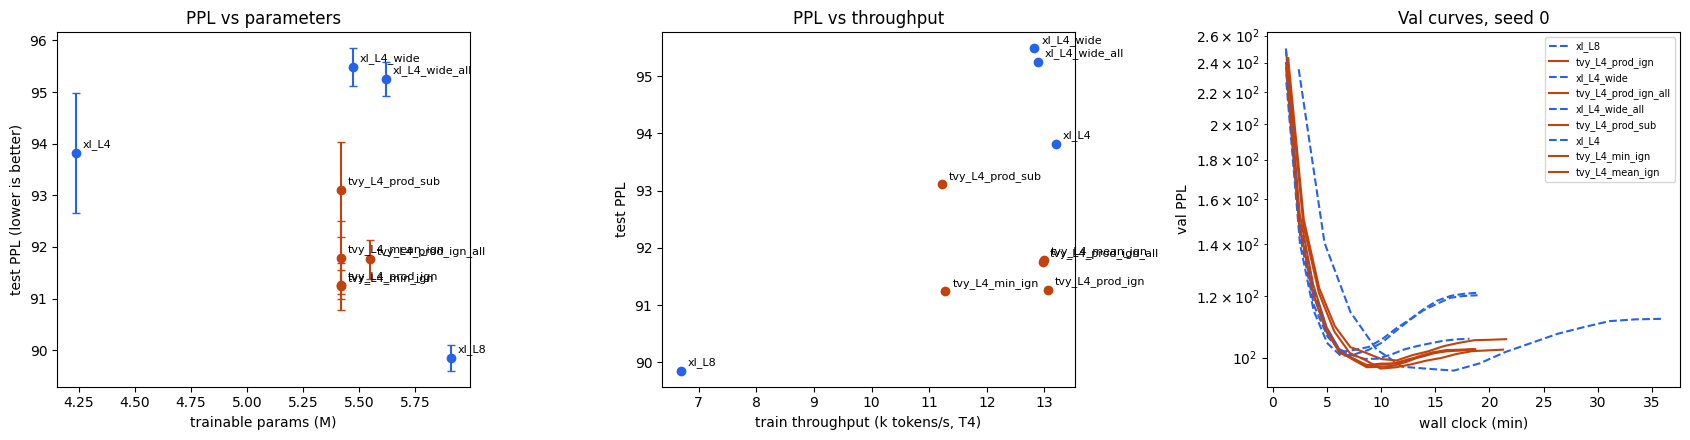

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
colors = {n: ("#c2410c" if n.startswith("tvy") else "#2563eb") for n in order}

ax = axes[0]
for n in order:
    a = agg.loc[n]
    ax.errorbar(a.params / 1e6, a.test_ppl, yerr=0 if np.isnan(a.test_ppl_std) else a.test_ppl_std,
                fmt="o", color=colors[n], capsize=3)
    ax.annotate(n, (a.params / 1e6, a.test_ppl), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xlabel("trainable params (M)"); ax.set_ylabel("test PPL (lower is better)"); ax.set_title("PPL vs parameters")

ax = axes[1]
for n in order:
    a = agg.loc[n]
    ax.scatter(a.train_tok_s / 1e3, a.test_ppl, color=colors[n])
    ax.annotate(n, (a.train_tok_s / 1e3, a.test_ppl), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xlabel("train throughput (k tokens/s, T4)"); ax.set_ylabel("test PPL"); ax.set_title("PPL vs throughput")

ax = axes[2]
for r in rows:
    if r["seed"] == min(SEEDS):
        h = pd.DataFrame(r["history"])
        ax.plot(h.elapsed_s / 60, h.val_ppl, label=r["arm"], color=colors.get(r["arm"], "gray"),
                ls="-" if r["arm"].startswith("tvy") else "--")
ax.set_xlabel("wall clock (min)"); ax.set_ylabel("val PPL"); ax.set_title(f"Val curves, seed {min(SEEDS)}")
ax.set_yscale("log"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "lm_results.png"), dpi=150); plt.show()

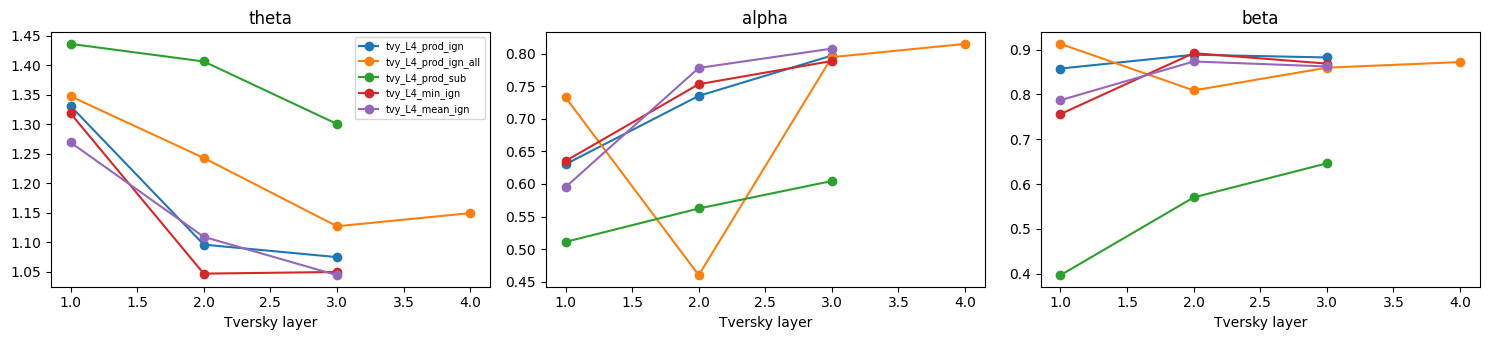

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharex=True)
for r_arm in [n for n in order if n.startswith("tvy")]:
    cs = np.array([r["constants"] for r in rows if r["arm"] == r_arm])
    if cs.size == 0:
        continue
    m = cs.mean(0)
    for j, name in enumerate(["theta", "alpha", "beta"]):
        axes[j].plot(range(1, len(m) + 1), m[:, j], marker="o", label=r_arm)
        axes[j].set_title(name); axes[j].set_xlabel("Tversky layer")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "lm_constants.png"), dpi=150); plt.show()